# PyWKSpectra
### Wheeler–Kiladis Space–Time Spectral Analysis in Python

**Version 1.0 | User Guide and Tutorial**

**Author:** Alejandro Jaramillo-Moreno  
**Department:** Departamento de Cambio Climático  
**Institution:** Instituto de Ciencias de la Atmósfera y Cambio Climático (ICAyCC)  
**University:** Universidad Nacional Autónoma de México (UNAM)  
**Location:** Mexico City, Mexico  
**ORCID:** [0000-0002-4175-7726](https://orcid.org/0000-0002-4175-7726)

---

## About PyWKSpectra

**PyWKSpectra** is a Python package for computing and visualizing Wheeler–Kiladis space–time spectra, widely used to investigate convectively coupled equatorial waves and tropical atmospheric variability.

The package provides tools for spectral preprocessing, equatorial symmetric and antisymmetric decomposition, space–time Fourier analysis, spectral background estimation, and visualization of equatorial wave dispersion relationships.

### About this tutorial

This notebook provides a step-by-step guide to using PyWKSpectra, from loading atmospheric data to computing Wheeler–Kiladis spectra and generating publication-quality figures.

The examples use daily outgoing longwave radiation (OLR) data from NOAA.

## Installation and Requirements

### 1. Install PyWKSpectra

PyWKSpectra requires **Python 3.10 or newer** and can be installed using pip:

`pip install PyWKSpectra`

The core scientific dependencies are installed automatically with the package:

| Package | Purpose |
|---|---|
| **NumPy** | Numerical calculations and Fourier transforms |
| **xarray** | Handling multidimensional atmospheric datasets |
| **Matplotlib** | Spectral visualization and publication-quality figures |
| **netCDF4** | Reading and writing NetCDF datasets |

### 2. Additional requirements for running this notebook

To execute this tutorial interactively, you need a Jupyter-compatible environment.

If you use **Visual Studio Code**, install the Python and Jupyter extensions and ensure that `ipykernel` is available in your selected Python environment.

Install `ipykernel` using pip:

`python -m pip install ipykernel`

Alternatively, if you use Conda:

`conda install -c conda-forge ipykernel`

The `ipykernel` package allows Jupyter and Visual Studio Code to execute Python code inside the selected environment. It is required for running this notebook but is not necessary for using PyWKSpectra in ordinary Python scripts.

### 3. Select the Python environment

Before running the notebook, select the Python kernel where PyWKSpectra and `ipykernel` are installed.

In Visual Studio Code, click **Select Kernel** in the upper-right corner of the notebook and choose the appropriate Python environment.

### 4. Verify the installation

After selecting the kernel, you can verify the installation by running:

`import pywkspectra as wk`

`print(wk.__version__)`

The expected output for this tutorial is:

`1.0`

---

**References**

- Matsuno, T. (1966). Quasi-geostrophic motions in the equatorial area. *Journal of the Meteorological Society of Japan*, 44, 25–43.
- Wheeler, M., & Kiladis, G. N. (1999). Convectively coupled equatorial waves: Analysis of clouds and temperature in the wavenumber–frequency domain. *Journal of the Atmospheric Sciences*, 56, 374–399.
- Kiladis, G. N., Wheeler, M. C., Haertel, P. T., Straub, K. H., & Roundy, P. E. (2009). Convectively coupled equatorial waves. *Reviews of Geophysics*, 47, RG2003.

In [1]:

# Import libraries
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pywkspectra as wk

# Verify PyWKSpectra version
print(f"PyWKSpectra version: {wk.__version__}")

PyWKSpectra version: 1.0


## 1. Input Data and Analysis Configuration

Before computing Wheeler–Kiladis spectra, the user must specify the input dataset and the basic parameters controlling the analysis.

PyWKSpectra provides the `compute_wk_spectra()` function, which performs the complete spectral analysis, including preprocessing, equatorial symmetry decomposition, space–time Fourier transforms, spectral smoothing, and background normalization.

### Input data requirements

PyWKSpectra accepts NetCDF files, GRIB files (with the optional `cfgrib` backend), and xarray `Dataset` or `DataArray` objects.

The input data must satisfy the following requirements:

- **Dimensions:** Time, latitude, and longitude.
- **Time:** Regularly spaced observations without missing timestamps.
- **Latitude:** Coverage in both hemispheres, allowing symmetric latitude pairs about the equator.
- **Longitude:** A regularly spaced grid covering the full 360°.
- **Missing values:** The selected data must not contain missing or non-finite values.

The package automatically identifies common coordinate names, arranges their dimensions, and selects the appropriate tropical latitude domain.

### Required parameters

Three parameters must be specified when calling `compute_wk_spectra()`:

| Parameter | Description |
|---|---|
| `source` | Path to the input data file, or an xarray object. |
| `varname` | Name of the atmospheric variable to analyze (e.g., `"olr"`). |
| `latBound` | Maximum absolute latitude, in degrees, for the equatorial analysis (e.g., `15` for 15°S–15°N). |

### Optional parameters

The following parameters control the spectral analysis. If they are not explicitly specified, PyWKSpectra uses the default values.

| Parameter | Default | Description |
|---|---|---|
| `nDayWin` | `96` | Length of each spectral window, in days. |
| `nDaySkip` | `-48` | Offset relative to the window length that determines the advance between consecutive windows. Negative values produce overlapping windows. |
| `max_wn` | `20` | Maximum absolute zonal wavenumber retained in the output. |
| `max_freq` | `0.5` | Maximum frequency retained in the output, in cycles per day. |
| `verbose` | `True` | Display processing information and progress messages. |

For the default configuration, each spectral window contains 96 days, with an overlap of 48 days between consecutive windows.

The default maximum frequency of 0.5 cycles per day corresponds to the Nyquist frequency for daily observations. Higher-frequency sampling can support higher maximum frequencies.

### Example dataset

In this tutorial, we use daily outgoing longwave radiation (OLR) data from NOAA, covering the period **January 2000–December 2004**.

The example dataset is provided with the repository:

`examples/data/noaa_olr_daily_2000_2004.nc`

We will use the standard analysis configuration with a tropical latitude domain of 15°S–15°N, 96-day spectral windows, and 48-day overlap.

The following cell defines the dataset location and analysis parameters.

In [2]:

# ==================================================
# Input data and analysis configuration
# ==================================================

# Input dataset
source = Path("data/noaa_olr_daily_2000_2004.nc")
varname = "olr"

# Tropical latitude domain
latBound = 15

# Spectral analysis parameters
nDayWin = 96
nDaySkip = -48

# Output spectral domain
max_wn = 20
max_freq = 0.5

# Processing information
verbose = True

# Verify input file
if not source.is_file():
    raise FileNotFoundError(f"Input file not found: {source}")

print(f"Input file: {source}")
print(f"Variable: {varname}")
print(f"Latitude domain: ±{latBound}°")
print(f"Window length: {nDayWin} days")
print(f"Window overlap: {-nDaySkip} days")


Input file: data/noaa_olr_daily_2000_2004.nc
Variable: olr
Latitude domain: ±15°
Window length: 96 days
Window overlap: 48 days


In [3]:
# ==================================================
# Compute Wheeler-Kiladis space-time spectra
# ==================================================

results = wk.compute_wk_spectra(
    source=source,
    varname=varname,
    latBound=latBound,
    nDayWin=nDayWin,
    nDaySkip=nDaySkip,
    max_wn=max_wn,
    max_freq=max_freq,
    verbose=verbose
)

# Display results
display(results)


PyWKSpectra - Input Data
Variable:           olr
Start date:         2000-01-01T00:00:00
End date:           2004-12-31T00:00:00
Requested latBound: +/-15 degrees
Applied latBound:   +/-15 degrees
Latitude range:     -15 to 15 degrees
Longitude range:    -180 to 177.5 degrees
Samples per day:    1
Data shape:         (1827, 13, 144)
Missing values:     None

PyWKSpectra - Spectral Sampling
Time samples:       1827
Latitude points:    13
Longitude points:   144
Samples per day:    1
Total days:         1827
-------------------------------------------------------
Window length:      96 days
Window samples:     96
Window skip:        -48 days
Window advance:     48 days
Window overlap:     48 days
-------------------------------------------------------
Complete windows:   37
Unused final days:  3

PyWKSpectra - Removing Dominant Signals
Linear trend:       Removed
Temporal mean:      Preserved
High-pass filter:   Applied
Critical frequency: 0.01042 cycles/day
Removed periods:    >= 96 da

<xarray.Dataset> Size: 127kB
Dimensions:                   (frequency: 48, wavenumber: 41)
Coordinates:
  * frequency                 (frequency) float64 384B 0.01042 0.02083 ... 0.5
  * wavenumber                (wavenumber) int64 328B -20 -19 -18 ... 18 19 20
Data variables:
    antisymmetric_power       (frequency, wavenumber) float64 16kB 0.01121 .....
    symmetric_power           (frequency, wavenumber) float64 16kB 0.01072 .....
    background_power          (frequency, wavenumber) float64 16kB 0.01344 .....
    antisymmetric_log_power   (frequency, wavenumber) float64 16kB -1.95 ... ...
    symmetric_log_power       (frequency, wavenumber) float64 16kB -1.97 ... ...
    background_log_power      (frequency, wavenumber) float64 16kB -1.872 ......
    antisymmetric_normalized  (frequency, wavenumber) float64 16kB 0.8343 ......
    symmetric_normalized      (frequency, wavenumber) float64 16kB 0.7977 ......
Attributes: (12/16)
    title:                        Wheeler-Kiladis Space-Time Spectra
    software:                     PyWKSpectra
    author:                       Alejandro Jaramillo Moreno
    institution:                  Instituto de Ciencias de la Atmosfera y Cam...
    variable:                     olr
    start_date:                   2000-01-01
    ...                           ...
    window_skip_days:             -48
    number_of_windows:            37
    temporal_taper:               Hann
    low_frequency_cutoff:         0.010416666666666666
    equator_in_latitude_average:  Excluded
    method:                       Wheeler-Kiladis space-time spectral analysis

## 2. Understanding the Spectral Output

The `compute_wk_spectra()` function returns an **xarray.Dataset** containing the Wheeler–Kiladis spectral analysis results.

This format provides a flexible, self-describing data structure with spectral coordinates, numerical results, and metadata describing the analysis configuration.

### Output variables

The dataset contains eight variables:

| Variable | Description |
|---|---|
| `symmetric_power` | Raw power spectrum of the equatorially symmetric component. |
| `antisymmetric_power` | Raw power spectrum of the equatorially antisymmetric component. |
| `background_power` | Smoothed background power spectrum. |
| `symmetric_log_power` | Base-10 logarithm of the symmetric power spectrum. |
| `antisymmetric_log_power` | Base-10 logarithm of the antisymmetric power spectrum. |
| `background_log_power` | Base-10 logarithm of the background power spectrum. |
| `symmetric_normalized` | Symmetric power divided by the background power. |
| `antisymmetric_normalized` | Antisymmetric power divided by the background power. |

All variables are organized using two coordinates:

- **`frequency`:** Temporal frequency in cycles per day.
- **`wavenumber`:** Global zonal wavenumber, with positive values representing eastward propagation and negative values representing westward propagation.

The normalized spectra are particularly useful for identifying enhanced spectral power relative to the estimated background. Values greater than 1 indicate power exceeding the background estimate.

### Saving and reusing results

Because the output is an xarray Dataset, users can save their spectral results directly in **NetCDF format**:

```python
results.to_netcdf("wk_spectra_results.nc")
```

The saved dataset can later be reopened without repeating the computationally intensive spectral analysis:

```python
import xarray as xr

results = xr.open_dataset("wk_spectra_results.nc")
```

This is especially useful when analyzing long atmospheric records or comparing multiple datasets.

### Custom analysis and visualization

Users have direct access to all spectral variables and coordinates, allowing them to perform additional calculations or create fully customized figures.

For example, the normalized symmetric spectrum can be accessed with:

```python
symmetric = results["symmetric_normalized"]
```

A custom figure can then be created using xarray and Matplotlib:

```python
symmetric.plot()
```

Users may also select particular frequency bands, zonal wavenumber ranges, or individual spectral values using standard xarray operations.

**PyWKSpectra therefore provides both ready-to-use plotting functions and complete access to the underlying spectral results**, supporting reproducible analyses and customized scientific visualizations.

The following sections demonstrate the plotting functions included in the package.


## 3. Visualizing Wheeler–Kiladis Spectra

PyWKSpectra provides ready-to-use plotting functions for visualizing space–time spectral analysis results. These functions generate publication-quality figures with customizable colors, frequency and wavenumber ranges, theoretical dispersion curves, and output resolution.

### 3.1. Background-Normalized Spectra

One of the most common approaches for identifying convectively coupled equatorial waves is to examine **background-normalized Wheeler–Kiladis spectra**.

The normalization is performed by dividing the symmetric and antisymmetric power spectra by a smoothed background power spectrum:

$$
\begin{aligned}
P_{\mathrm{norm}}^{\mathrm{S}}(k,f) &=
\frac{P_{\mathrm{S}}(k,f)}
{P_{\mathrm{background}}(k,f)}
\\[8pt]
P_{\mathrm{norm}}^{\mathrm{A}}(k,f) &=
\frac{P_{\mathrm{A}}(k,f)}
{P_{\mathrm{background}}(k,f)}
\end{aligned}
$$

where:

- $P_{\mathrm{S}}$ is the symmetric power spectrum.
- $P_{\mathrm{A}}$ is the antisymmetric power spectrum.
- $P_{\mathrm{background}}$ is the smoothed background power spectrum.
- $k$ is the zonal wavenumber.
- $f$ is the temporal frequency.

This procedure highlights regions of enhanced spectral power relative to the background, making the signatures of equatorial waves easier to identify. Values greater than 1 indicate power exceeding the estimated background.

### Plotting normalized spectra

PyWKSpectra provides the `plot_wk_spectra()` function to visualize the background-normalized spectra.

**Basic usage:**

```python
fig, axes = wk.plot_wk_spectra(results)
```

The function generates a two-panel figure:

- **Left panel:** Equatorially symmetric, background-normalized power spectrum.
- **Right panel:** Equatorially antisymmetric, background-normalized power spectrum.

By default, theoretical equatorial-wave dispersion curves following Matsuno (1966) are superimposed for equivalent depths of 12, 25, and 50 meters.

The horizontal axis represents zonal wavenumber, with positive values corresponding to eastward propagation and negative values to westward propagation. The vertical axis represents temporal frequency in cycles per day.

### Customizing the figure

The appearance and spectral domain can be modified using optional parameters.

For example:

```python
fig, axes = wk.plot_wk_spectra(
    results,
    figsize=(12, 5.4),
    dpi=120,
    max_wn_plot=20,
    max_freq_plot=0.5,
    contour_range=(0, 2, 0.1),
    cmap="RdBu_r",
    matsuno_lines=True,
    he=(12, 25, 50),
    meridional_modes=(1,)
)
```

The `contour_range` parameter specifies the minimum, maximum, and interval of the spectral power levels.

The theoretical dispersion curves can be disabled using `matsuno_lines=False`, allowing the normalized power distribution to be examined independently.

Additional options allow users to display reference-period lines, contour lines, and selected wave labels.

### Saving figures

PyWKSpectra can automatically save figures in both **PNG and PDF formats** using the `save_dir` parameter.

For example:

```python
fig, axes = wk.plot_wk_spectra(
    results,
    dpi=300,
    save_dir="figures"
)
```

This creates the specified directory, if necessary, and saves two files:

- `wk_normalized_spectra.png` — Raster image at the selected resolution.
- `wk_normalized_spectra.pdf` — Vector-format figure suitable for scientific publications.

The default resolution is **120 dpi**, but higher values, such as 300 dpi, can be selected when preparing figures for publication.

The `show` parameter controls whether the figure is displayed during execution. Setting `show=False` is useful when generating figures automatically without displaying them.

### Further customization with Matplotlib

The function returns standard Matplotlib `Figure` and `Axes` objects:

```python
fig, axes = wk.plot_wk_spectra(results)
```

These objects allow users to make additional modifications using Matplotlib, including changing axis labels, titles, annotations, and other graphical elements.

Users can also create entirely customized spectral figures directly from the xarray Dataset returned by `compute_wk_spectra()`.


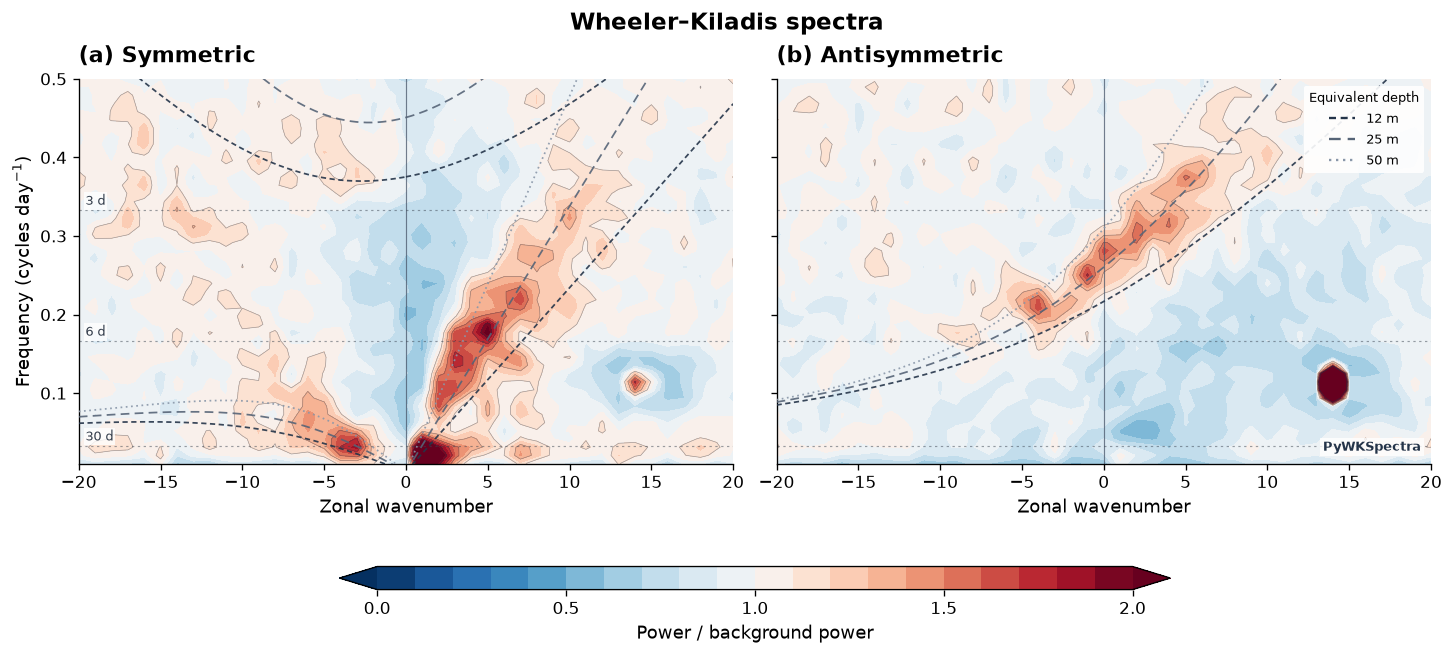

In [5]:
# Plot background-normalized Wheeler-Kiladis spectra
fig, axes = wk.plot_wk_spectra(results, show=True)

### 3.2. Raw Power Spectra

In addition to background-normalized spectra, PyWKSpectra allows users to visualize the **raw Wheeler–Kiladis power spectra**, before normalization by the estimated spectral background.

While background-normalized spectra highlight enhanced spectral power associated with equatorial waves, raw spectra provide information about the overall distribution of spectral power across frequencies and zonal wavenumbers.

The `plot_raw_spectra()` function generates three separate figures:

- **Symmetric power spectrum:** Spectral power associated with the equatorially symmetric component.
- **Antisymmetric power spectrum:** Spectral power associated with the equatorially antisymmetric component.
- **Background power spectrum:** Smoothed spectral power used to normalize the symmetric and antisymmetric spectra.

All three spectra are displayed on a **base-10 logarithmic scale**, allowing variations across a broad range of spectral power to be visualized more clearly.

Examining these spectra can help identify dominant timescales and spatial scales, assess the spectral background, and distinguish regions of strong absolute power from those exhibiting enhanced power relative to the background.

PyWKSpectra uses a common color scale across the three figures to facilitate comparison.

As with the normalized spectra, users can customize the frequency and wavenumber ranges, color scales, figure resolution, and output formats.

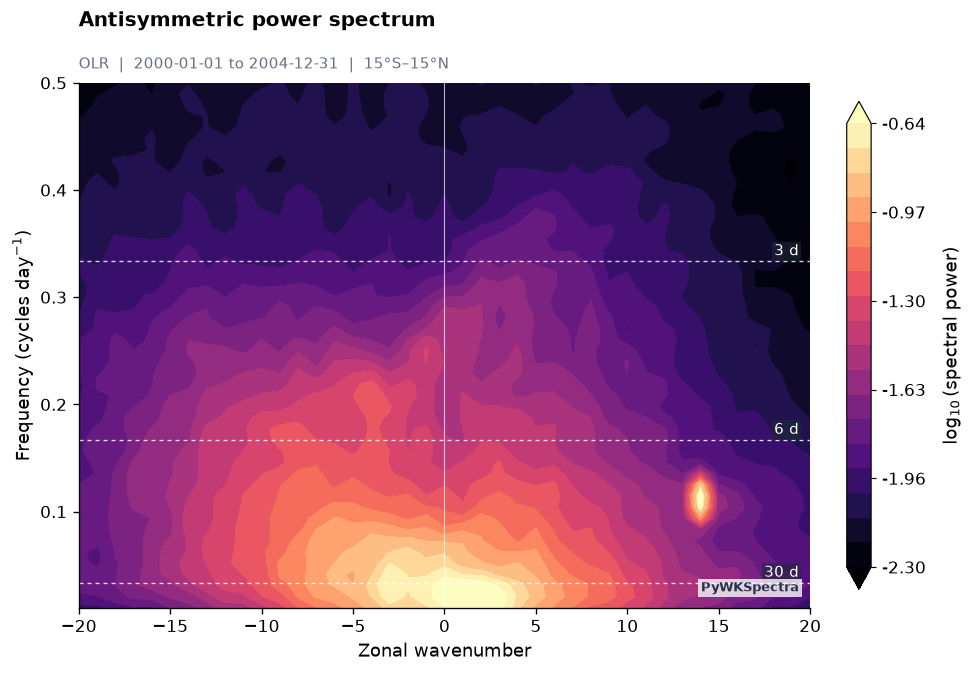

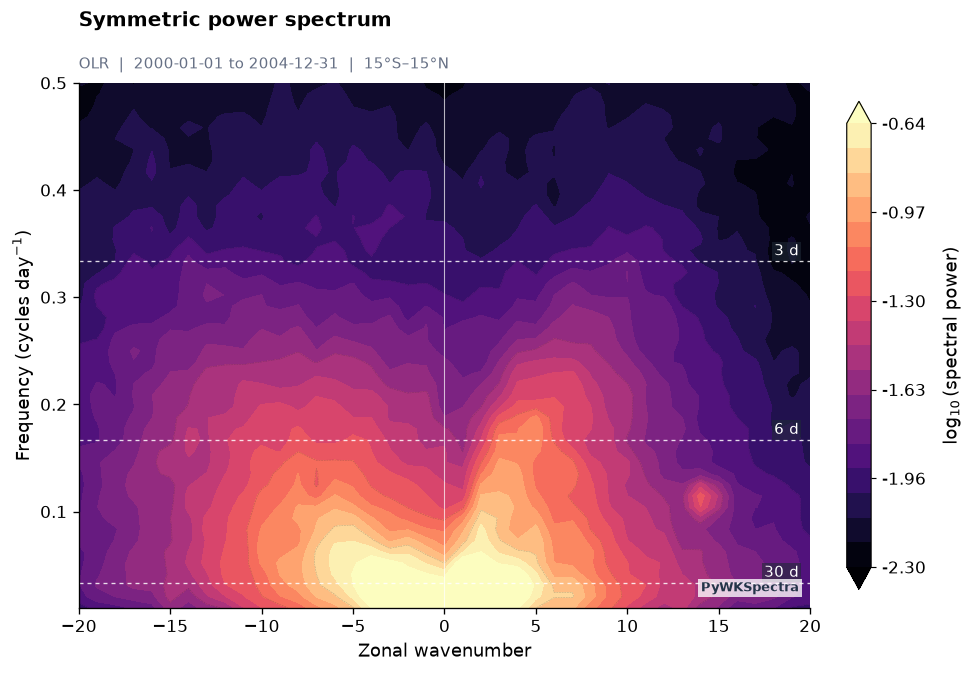

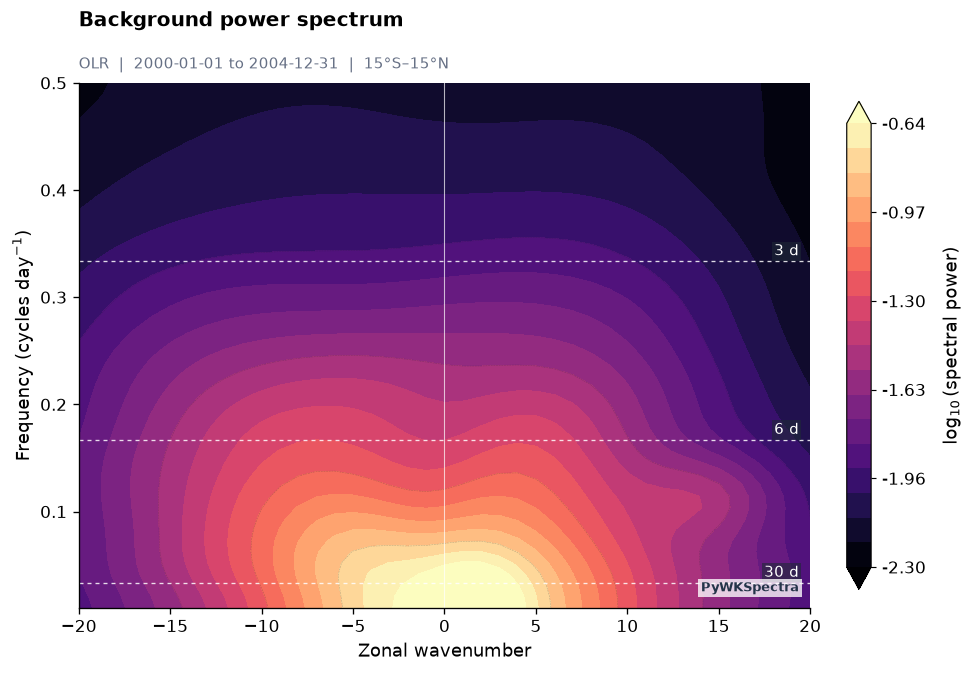

In [6]:
# Plot raw Wheeler-Kiladis power spectra
figures = wk.plot_raw_spectra(results, show=True)

### 3.3. Matsuno Dispersion Diagrams

In addition to Wheeler–Kiladis power spectra, PyWKSpectra provides tools for calculating and visualizing the theoretical dispersion relationships of equatorial waves based on the work of Matsuno (1966).

These dispersion diagrams describe the relationship between **zonal wavenumber and temporal frequency** for different equatorial wave modes, providing a theoretical framework for interpreting observed spectral signals.

The `plot_matsuno()` function generates dispersion diagrams for several equatorial wave families:

- **Kelvin waves**
- **Equatorial Rossby waves (ER)**
- **Mixed Rossby–Gravity waves (MRG)**
- **Eastward inertia–gravity waves (EIG)**
- **Westward inertia–gravity waves (WIG)**

The dispersion relationships depend on the **equivalent depth**, which controls the characteristic gravity-wave speed, and on the meridional mode number.

### Generating dispersion diagrams

The function `plot_matsuno()` allows users to visualize the theoretical dispersion curves for a specified equivalent depth.

The main parameters are:

| Parameter | Default | Description |
|---|---|---|
| `he` | `25` | Equivalent depth in meters. |
| `max_wn` | `20` | Maximum absolute zonal wavenumber. |
| `max_freq` | `0.5` | Maximum frequency in cycles per day. |
| `meridional_modes` | `(1, 2, 3)` | Meridional mode numbers to display. |
| `figsize` | `(9, 6)` | Figure dimensions in inches. |
| `dpi` | `120` | Figure resolution. |
| `save_path` | `None` | Optional file path for saving the figure. |

These diagrams can be generated **independently of the spectral analysis**, making them useful for theoretical studies, teaching, and interpreting equatorial wave dynamics.

As with the other plotting functions, `plot_matsuno()` returns Matplotlib figure and axes objects, allowing further graphical customization.

The following example illustrates how to generate a Matsuno dispersion diagram for an equivalent depth of 25 meters.

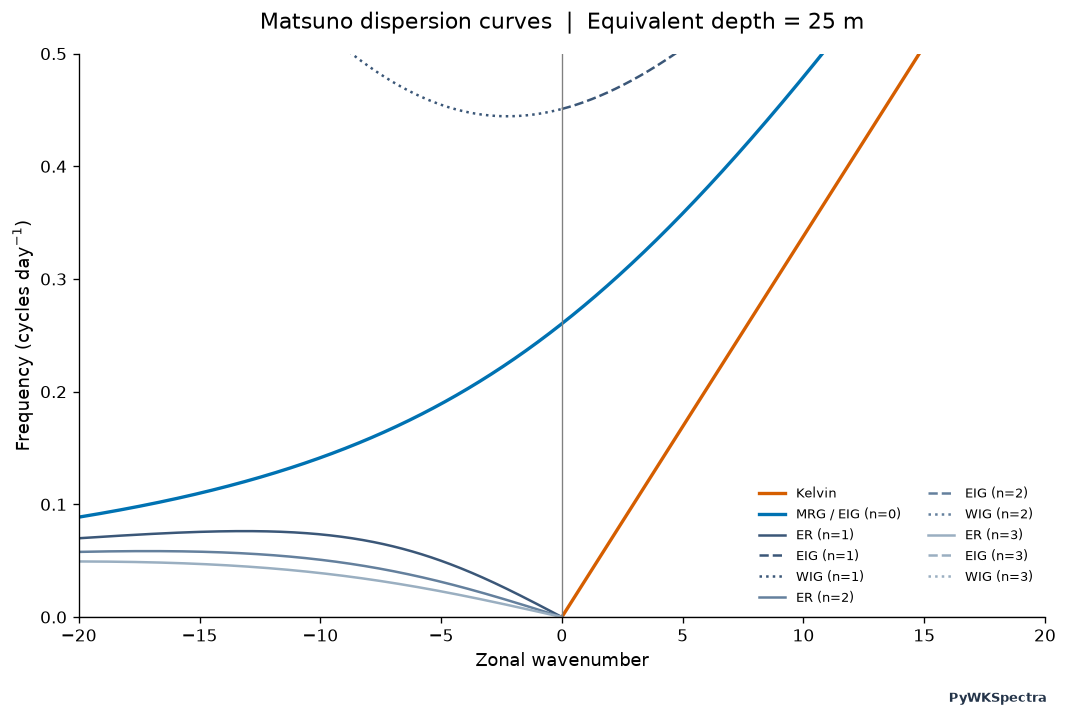

In [7]:
# Plot theoretical Matsuno dispersion curves
fig, ax = wk.plot_matsuno(he=25)

## 4. Final Remarks — A Personal Note from the Author

### Thank you for using PyWKSpectra!

I sincerely hope that **PyWKSpectra** becomes a useful tool for your research, teaching, and exploration of tropical atmospheric dynamics.

The main goal of this project is simple: **to make Wheeler–Kiladis spectral analysis more accessible, reproducible, and easier to use within the Python scientific community.**

With PyWKSpectra, you can compute symmetric and antisymmetric space–time power spectra, estimate the spectral background, obtain background-normalized spectra, and generate publication-quality figures, including theoretical Matsuno dispersion diagrams.

Of course, there is still plenty of room for improvement! For example, **PyWKSpectra 1.0 does not perform Wheeler–Kiladis wavenumber–frequency filtering or reconstruct individual wave signals in physical space**. These and other capabilities may be explored in future versions.

I warmly welcome suggestions, bug reports, new ideas, and opportunities for scientific collaboration.

### A few words about the project

PyWKSpectra grew out of my personal interest in tropical atmospheric dynamics and my desire to develop scientific tools that others could use.

This work has been developed independently, during my free time, **without dedicated funding or institutional support**, alongside substantial academic, research, teaching, and administrative responsibilities.

Behind this package are many hours of unpaid work, experimentation, learning, and scientific problem-solving. I have invested that time because I genuinely believe that sharing scientific tools helps our community move forward.

An earlier implementation of my work, known as `wk_spectra`, has circulated with attribution that did not always clearly reflect my original contribution. With PyWKSpectra, I hope to establish a clear record of its authorship and development, while continuing to improve and share these scientific tools.

My intention is not to dwell on the past, but to build something useful for the future.

### How you can support this project

**I am not asking for financial contributions.** What would mean much more to me is recognition of the scientific and technical work behind this package.

If PyWKSpectra contributes to your research, **please cite the package appropriately and acknowledge its original authorship**. Proper citation is one of the most meaningful ways to support independent scientific software development.

If you use PyWKSpectra in a scientific publication, I would be delighted to hear from you! Please consider sending me the reference or DOI. I would love to maintain a list of publications that have benefited from the package.

I would also be very happy to explore scientific collaborations, particularly those involving tropical atmospheric dynamics, convectively coupled equatorial waves, and climate variability.

And if you use PyWKSpectra in a classroom, for a student project, or simply out of curiosity and enjoyment, that would make me equally happy. Knowing that these hours of work have helped someone learn, investigate, or discover something new is already a wonderful reward.

**Science advances when we share knowledge, recognize contributions, and work together.**

Thank you for being part of this effort. I hope PyWKSpectra serves you well, and I look forward to seeing where the community takes it next!

---

### Contact and collaboration

**Alejandro Jaramillo-Moreno**  
Departamento de Cambio Climático  
Instituto de Ciencias de la Atmósfera y Cambio Climático (ICAyCC)  
Universidad Nacional Autónoma de México (UNAM)  
Mexico City, Mexico

**Email:** [ajaramillo@atmosfera.unam.mx](mailto:ajaramillo@atmosfera.unam.mx)  
**ORCID:** [0000-0002-4175-7726](https://orcid.org/0000-0002-4175-7726)

*Thank you for using PyWKSpectra. Happy wave hunting!*